# Bab 3 – Teknik Reduksi Dimensi

## Ringkasan Bab
Data berdimensi tinggi lambat diproses, penuh noise, dan sulit divisualisasikan. Bab ini memperkenalkan **reduksi dimensi**:
teorinya (curse of dimensionality, proyeksi, varians), **PCA** (tanpa label, memaksimalkan varians),
**LDA** (memakai label, memaksimalkan pemisahan kelas), perbedaan keduanya, **t-SNE** untuk visualisasi,
serta pengaruhnya terhadap performa model. Bab ditutup dengan dua latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score

## 1. Pengantar Reduksi Dimensi
**Mengapa penting?**
* **Curse of dimensionality**: makin banyak dimensi, data makin renggang dan jarak antar titik kehilangan makna, sehingga model butuh data jauh lebih banyak.
* **Overfitting dan noise**: fitur yang berlebihan membuat model ikut menghafal noise.
* **Kecepatan dan memori**: fitur lebih sedikit berarti pelatihan lebih cepat.
* **Visualisasi**: manusia hanya bisa melihat data dalam 2-3 dimensi.

**Landasan teori.** Ada dua kelompok cara:
1. *Seleksi fitur*: memilih sebagian fitur asli.
2. *Ekstraksi fitur*: membuat fitur baru lewat proyeksi, misalnya PCA dan LDA (linear) atau t-SNE/UMAP (non-linear).

In [2]:
# Demonstrating the curse of dimensionality: distance concentration
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000]:
    P = rng.random((500, d))
    dist = np.linalg.norm(P[1:] - P[0], axis=1)
    print(f"d={d:5d}  (max-min)/min distance = {(dist.max()-dist.min())/dist.min():.2f}")

d=    2  (max-min)/min distance = 66.13
d=   10  (max-min)/min distance = 2.32
d=  100  (max-min)/min distance = 0.36
d= 1000  (max-min)/min distance = 0.11


## 2. Transformasi Data dengan PCA
**Principal Component Analysis (PCA)** mencari arah-arah yang saling tegak lurus (komponen utama) dengan varians terbesar.

Langkahnya: pusatkan data → hitung matriks kovarians Σ → dekomposisi eigen (atau SVD) → urutkan eigenvector berdasarkan eigenvalue λ →
proyeksikan: Z = X·W_k. **Rasio varians yang dijelaskan** oleh komponen ke-*i* adalah λᵢ / Σλ.
Data harus distandarkan lebih dulu karena PCA peka terhadap skala.

Components needed for 95% variance: 40 of 64


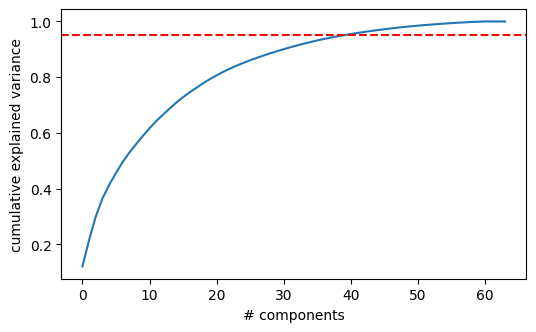

In [3]:
digits = load_digits()
X, y = digits.data, digits.target          # 1797 samples x 64 pixels
Xs = StandardScaler().fit_transform(X)
pca = PCA().fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = np.argmax(cum >= 0.95) + 1
print("Components needed for 95% variance:", k95, "of", X.shape[1])

plt.figure(figsize=(6, 3.5)); plt.plot(cum); plt.axhline(.95, ls="--", c="r")
plt.xlabel("# components"); plt.ylabel("cumulative explained variance"); plt.show()

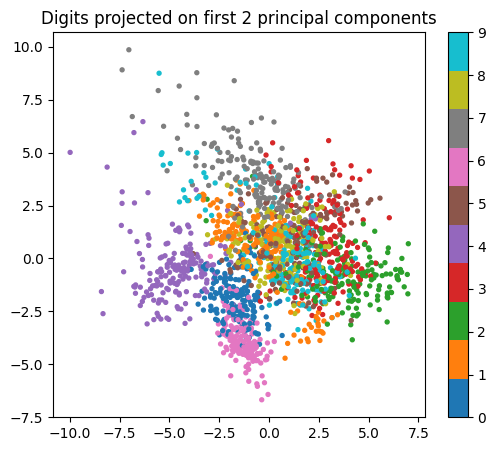

Auto k for 95%: 40


In [4]:
pca2 = PCA(n_components=2).fit_transform(Xs)
plt.figure(figsize=(6, 5)); sc = plt.scatter(pca2[:, 0], pca2[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(sc); plt.title("Digits projected on first 2 principal components"); plt.show()
# PCA(n_components=0.95) picks k automatically
print("Auto k for 95%:", PCA(n_components=0.95).fit(Xs).n_components_)

## 3. Memaksimalkan Keterpisahan Kelas dengan LDA
**Linear Discriminant Analysis (LDA)** bersifat *supervised* (memakai label). LDA mencari proyeksi yang memaksimalkan
perbandingan **sebaran antar kelas (S_B)** terhadap **sebaran dalam kelas (S_W)**: maksimalkan  wᵀS_Bw / wᵀS_Ww.
Jumlah komponennya paling banyak **min(jumlah kelas − 1, jumlah fitur)**, dan LDA juga bisa dipakai sebagai classifier.

Explained variance ratio (LDA): [0.687 0.313]


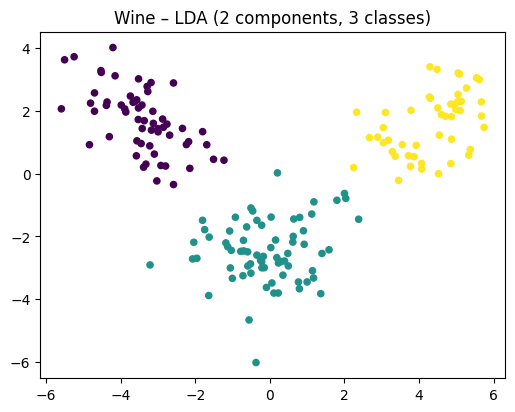

In [5]:
wine = load_wine(); Xw, yw = wine.data, wine.target
Xws = StandardScaler().fit_transform(Xw)
lda = LDA(n_components=2).fit(Xws, yw)
Z = lda.transform(Xws)
print("Explained variance ratio (LDA):", lda.explained_variance_ratio_.round(3))
plt.figure(figsize=(6, 4.5)); plt.scatter(Z[:, 0], Z[:, 1], c=yw, cmap="viridis", s=20)
plt.title("Wine – LDA (2 components, 3 classes)"); plt.show()

## 4. Perbedaan PCA dan LDA
| | PCA | LDA |
|---|---|---|
| Supervisi | Tanpa label | Memakai label |
| Tujuan | Memaksimalkan total varians | Memaksimalkan pemisahan kelas |
| Komponen maksimum | min(jumlah sampel, jumlah fitur) | jumlah kelas − 1 |
| Asumsi | tidak ada (linear) | tiap kelas berdistribusi Gaussian dengan kovarians sama |
| Cocok untuk | kompresi, mengurangi noise | persiapan sebelum klasifikasi |

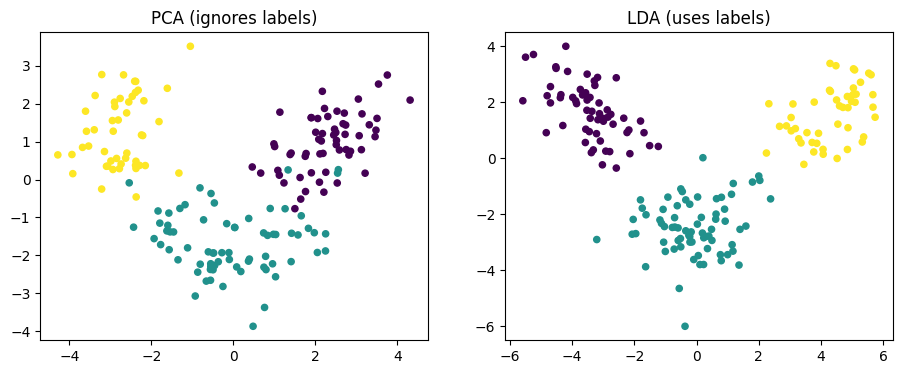

In [6]:
pw = PCA(n_components=2).fit_transform(Xws)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pw[:, 0], pw[:, 1], c=yw, cmap="viridis", s=20); ax[0].set_title("PCA (ignores labels)")
ax[1].scatter(Z[:, 0], Z[:, 1], c=yw, cmap="viridis", s=20);  ax[1].set_title("LDA (uses labels)")
plt.show()

## 5. t-SNE dan Visualisasi Data
**t-distributed Stochastic Neighbor Embedding (t-SNE)** adalah metode *non-linear* untuk visualisasi data ke 2-D atau 3-D.
1. Ubah jarak di ruang berdimensi tinggi menjadi kemiripan antar titik *p_ij* (distribusi Gaussian, diatur oleh **perplexity**).
2. Gunakan distribusi Student-t berekor tebal untuk kemiripan di dimensi rendah *q_ij*.
3. Minimalkan KL(P‖Q) dengan gradient descent.

**Panduan:** perplexity sekitar 5-50 dan coba beberapa nilai. Ukuran cluster dan jarak antar cluster *tidak* bisa ditafsirkan secara harfiah.
t-SNE tidak punya `transform()` untuk data baru, jadi hanya dipakai untuk visualisasi. Biasanya PCA dijalankan lebih dulu
(misalnya ke 30-50 dimensi) supaya lebih cepat.

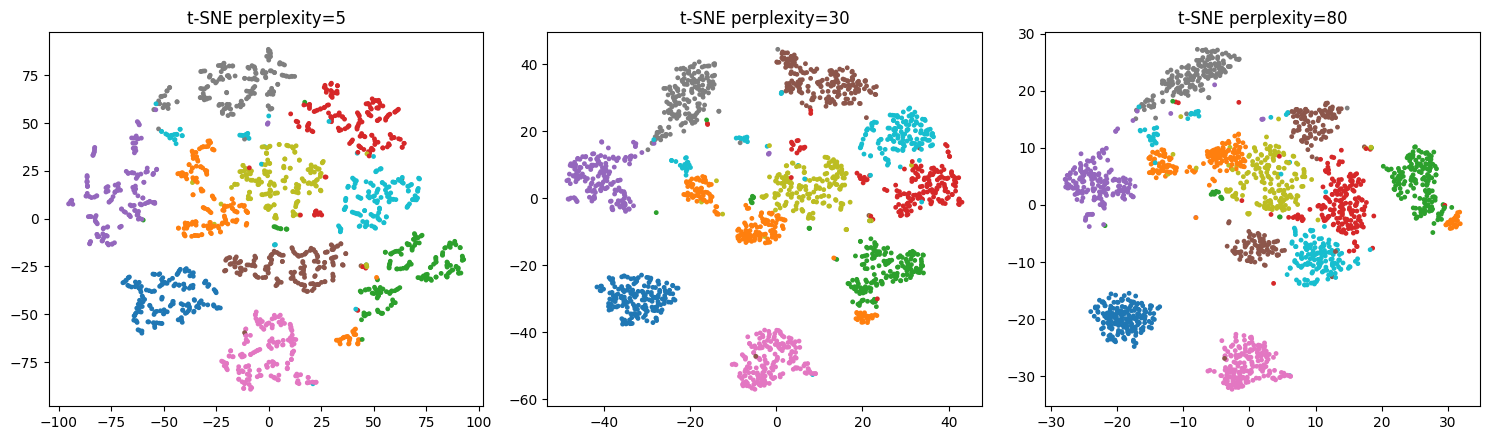

In [7]:
X50 = PCA(n_components=30, random_state=0).fit_transform(Xs)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, p in zip(ax, [5, 30, 80]):
    E = TSNE(n_components=2, perplexity=p, random_state=0, init="pca").fit_transform(X50)
    a.scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=6); a.set_title(f"t-SNE perplexity={p}")
plt.tight_layout(); plt.show()

## 6. Pengaruh terhadap Performa Model
Reduksi dimensi mengorbankan sedikit informasi demi kecepatan, dan kadang membuat model lebih baik dalam menggeneralisasi.
Berikut perbandingan akurasi dan waktu pelatihan untuk berbagai jumlah komponen PCA.

In [8]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
rows = []
for k in [None, 40, 20, 10, 5, 2]:
    steps = [StandardScaler()] + ([PCA(n_components=k)] if k else []) + [LogisticRegression(max_iter=2000)]
    m = make_pipeline(*steps)
    t = time.time(); m.fit(Xtr, ytr); dt = time.time() - t
    rows.append({"PCA comps": k or "none (64)", "test acc": round(m.score(Xte, yte), 3), "fit time (s)": round(dt, 3)})
pd.DataFrame(rows)

,PCA comps,test acc,fit time (s)
0,none (64),0.978,0.021
1,40,0.960,0.022
2,20,0.942,0.024
3,10,0.858,0.031
4,5,0.784,0.035
5,2,0.511,0.025


## 7. Latihan Praktik Reduksi Dimensi

### Latihan 1 – PCA dengan Logistic Regression
Jumlah komponen dipilih lewat cross-validation.

In [9]:
from sklearn.model_selection import GridSearchCV
pipe = make_pipeline(StandardScaler(), PCA(), LogisticRegression(max_iter=3000))
gs = GridSearchCV(pipe, {"pca__n_components": [5, 10, 20, 30, 40, 64]}, cv=5, n_jobs=-1).fit(Xtr, ytr)
print("Best n_components:", gs.best_params_, "| CV acc:", round(gs.best_score_, 3), "| test acc:", round(gs.score(Xte, yte), 3))

Best n_components: {'pca__n_components': 64} | CV acc: 0.97 | test acc: 0.976


### Latihan 2 – t-SNE untuk Visualisasi
Visualisasikan dataset wine dalam 2-D dengan t-SNE, lalu bandingkan dengan hasil LDA dan PCA di atas.

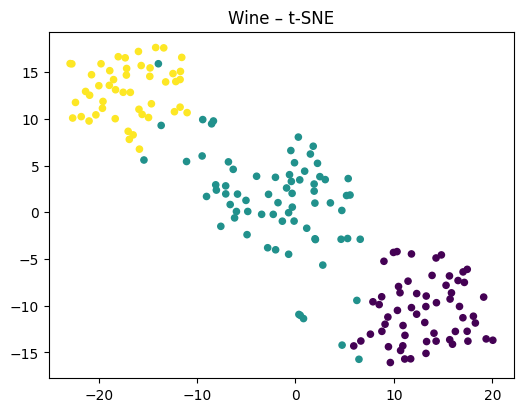

In [10]:
Ew = TSNE(n_components=2, perplexity=20, random_state=0, init="pca").fit_transform(Xws)
plt.figure(figsize=(6, 4.5)); plt.scatter(Ew[:, 0], Ew[:, 1], c=yw, cmap="viridis", s=20)
plt.title("Wine – t-SNE"); plt.show()

**Kesimpulan:** PCA dipakai untuk kompresi dan mengurangi noise, LDA dipakai saat label tersedia dan kita ingin kelas lebih terpisah,
sedangkan t-SNE hanya untuk *melihat* bentuk data.